# One South hand, every way the other cards could lie

The other two notebooks deal many random hands. This one fixes **one hand**, South's, and asks:

*Given only these 13 cards, with the other 39 cards in every different place they could be, how likely is each partner holding, each auction, each contract, and each result?*

- **Exact** where counting can do it: what partner holds (points, spade length) is a hypergeometric draw from the 39 unseen cards.
- **Sampled** where it has to be played: 20,000 random placements of the 39 cards, each one bid by the points-and-fit system and played, once by a simple strategy and once by a player who counts cards.
- **Double-dummy** on 1,000 of the placements: what the cards allow with perfect play, to judge the bids.

South is dealer and nobody is vulnerable. East and West pass throughout, as in the bidding system.

*Needs the double-dummy solver (the `dd` dependency group), Python 3.12 or 3.13.*

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

from Bridge import DoubleDummy as DD
from Bridge import Evaluation as E
from Bridge import Probability as P
from Bridge.Auction import run_auction
from Bridge.Bid import Bid
from Bridge.Contract import SYMBOLS
from Bridge.Deck import Deck
from Bridge.Hand import Hand
from Bridge.Harness import run_batches
from Bridge.Position import Position
from Bridge.Round import Round, countingHigh, simpleHigh
from Bridge.Scoring import score
from Bridge.Table import Table

assert DD.AVAILABLE, "this notebook needs the double-dummy solver: `uv sync` on Python 3.12 or 3.13"
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
SEATS = Position.positions
STRAINS = Bid.strains  # clubs, diamonds, hearts, spades, notrump

## Display helpers

The same small HTML helpers as in the *Play one hand* notebook.

In [2]:
RED = "#c0392b"
SYMBOL = SYMBOLS  # clubs, diamonds, hearts, spades, notrump -> symbols

def suit_html(suit):
    colour = RED if suit in ("hearts", "diamonds") else "inherit"
    return f'<span style="color:{colour}">{SYMBOL[suit]}</span>'

def rank_text(card):
    return "10" if str(card.value) == "0" else str(card.value)

def card_html(card, bold=False):
    text = f"{suit_html(str(card.suit))}{rank_text(card)}"
    return f"<b>{text}</b>" if bold else text

def bid_html(bid):
    if bid is None:
        return ""
    if bid.isPass:
        return '<span style="color:#888">pass</span>'
    return f"{bid.value}{suit_html(bid.suit) if bid.suit != 'notrump' else 'NT'}"

def holdings_html(cards, played=()):
    """one line per suit, highest first; cards in `played` are greyed out"""
    played = {c.code for c in played}
    lines = []
    for suit in ("spades", "hearts", "diamonds", "clubs"):
        ranks = sorted([c for c in cards if str(c.suit) == suit], key=lambda c: -c.rank)
        text = " ".join(f'<span style="color:#aaa;text-decoration:line-through">{rank_text(c)}</span>' if c.code in played
                        else rank_text(c) for c in ranks) or "&mdash;"
        lines.append(f"{suit_html(suit)}&nbsp;{text}")
    return "<br>".join(lines)

def hand_box(seat, hand, played=(), note=""):
    cards = hand.original
    shape = "-".join(str(n) for _, n in hand.distro())
    caption = f"<b>{seat.title()}</b> <small style='color:#888'>{hand.hcp() if len(hand.original) == 13 else ''} points, {shape}</small>"
    return (f'<div style="border:1px solid #999;border-radius:6px;padding:6px 12px;text-align:left;min-width:170px;'
            f'display:inline-block;line-height:1.5">{caption}<br>{holdings_html(cards, played)}{note}</div>')

def compass(boxes, centre=""):
    cell = lambda html: f'<td style="padding:4px;text-align:center;vertical-align:middle">{html}</td>'
    return ('<table style="border-collapse:collapse;margin:8px 0"><tr>' + cell("") + cell(boxes["north"]) + cell("") + "</tr><tr>"
            + cell(boxes["west"]) + cell(centre) + cell(boxes["east"]) + "</tr><tr>" + cell("") + cell(boxes["south"]) + cell("")
            + "</tr></table>")

def deal_html(hands, dealer=None, vulnerable="none"):
    boxes = {seat: hand_box(seat, hands[i]) for i, seat in enumerate(SEATS)}
    centre = f'<div style="border:1px dashed #bbb;padding:10px;color:#666">Dealer: <b>{dealer}</b><br>Vulnerable: <b>{vulnerable}</b></div>' if dealer else ""
    return compass(boxes, centre)

def table_html(header, rows, styles=None, caption=""):
    th = "".join(f'<th style="padding:3px 10px;border-bottom:2px solid #888;text-align:center">{h}</th>' for h in header)
    body = ""
    for r, row in enumerate(rows):
        body += "<tr>" + "".join(
            f'<td style="padding:3px 10px;text-align:center;{(styles or {}).get((r, c), "")}">{cell}</td>' for c, cell in enumerate(row)) + "</tr>"
    cap = f'<caption style="caption-side:top;text-align:left;font-weight:bold;padding-bottom:4px">{caption}</caption>' if caption else ""
    return f'<table style="border-collapse:collapse;margin:6px 0">{cap}<tr>{th}</tr>{body}</table>'

def dd_html(table):
    """tricks the declaring side takes, by strain (rows) and declarer (columns)"""
    rows, styles = [], {}
    order = [("notrump", 4), ("spades", 3), ("hearts", 2), ("diamonds", 1), ("clubs", 0)]
    for r, (strain, s) in enumerate(order):
        rows.append([suit_html(strain) if strain != "notrump" else "NT"] + [int(table[s][seat]) for seat in range(4)])
        for c in range(4):
            tricks = int(table[s][c])
            styles[(r, c + 1)] = f"background:rgba(39,174,96,{0.08 + 0.07 * max(tricks - 6, 0):.2f})" + (";font-weight:bold" if tricks >= 7 else "")
    return table_html(["", "North", "East", "South", "West"], rows, styles, "Tricks the declaring side takes, best play by everyone")

def auction_html(result):
    rows = []
    for row in result.rounds():
        rows.append([bid_html(b) if b is not None else "" for b in row])
    header = [f"{s.title()}{' (dealer)' if s == result.dealer else ''}" for s in SEATS]
    return table_html(header, rows, caption="The auction")

def reasons_html(result):
    items = "".join(f"<li><b>{c.seat.title()}</b> {bid_html(c.bid)}: {c.reason}</li>" for c in result.calls
                    if not c.reason.startswith("the other side opened"))
    return f"<ol style='line-height:1.6'>{items}</ol>"

def play_html(rnd, contract):
    """the trick-by-trick table of a played Round"""
    rows, styles = [], {}
    ours = 0
    for t, (trick, winner) in enumerate(zip(rnd.tricks, rnd.winners)):
        won = Position.side(winner) == contract.side
        ours += won
        cells = []
        for c, seat in enumerate(SEATS):
            card = trick.getCard(seat)
            lead = "&rarr;&nbsp;" if seat == trick.leader else ""
            cells.append(lead + card_html(card, bold=(seat == winner)))
            if seat == winner:
                styles[(t, c + 1)] = "background:rgba(39,174,96,0.18)"
        rows.append([t + 1] + cells + [winner.title(), f"{ours}&ndash;{t + 1 - ours}"])
    header = ["Trick"] + [s.title() for s in SEATS] + ["Won by", f"{contract.declarer.title()}'s side so far"]
    return table_html(header, rows, styles, "&rarr; marks the lead, the winning card is bold")

In [3]:
from Bridge.Card import Card
from Bridge.Contract import Contract

SOUTH = "AsKs0s9s7s4s2sAh4h9dAc9c3c"   # value then suit, 0 is the ten
SOUTH_CARDS = [Card.fromCode(SOUTH[i:i + 2]) for i in range(0, len(SOUTH), 2)]
south = Hand(SOUTH_CARDS)
C = E.COL

## 1. The hand

Fifteen points and a seven card spade suit headed by the ace and king: a strong opening bid, and a hand whose value depends a great deal on what partner holds.

In [4]:
display(HTML(hand_box("south", south)))

## 2. What partner can hold: exact

Partner's 13 cards are a random draw from the **39 cards South cannot see**, so partner's points are a multivariate hypergeometric over what is left of the honors (1 ace, 3 kings, 4 queens, 4 jacks: 25 points among 12 honors and 27 blanks). `Probability.partner_hcp_pmf` sums that exactly, and `partner_suit_length_pmf` gives partner's spades (6 are left, so partner holds 0 to 6).

Alongside the exact bars are the same quantities counted over 20,000 random layouts, as a check that the sampler deals what it should.

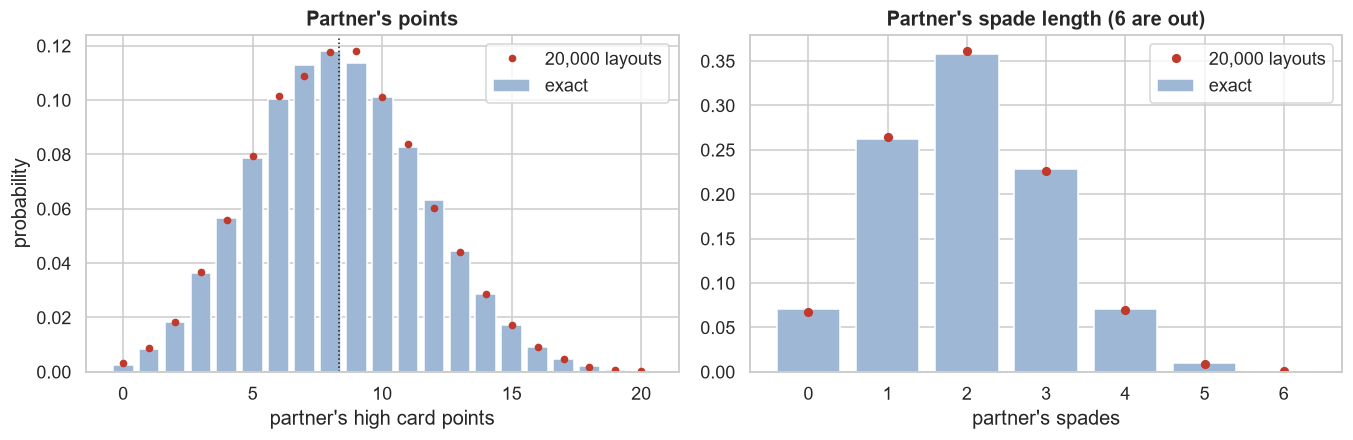

partner's points: mean 8.33, standard deviation 3.27; the pair holds 23.3 on average
P(partner has 10 or more points) = 35.4%     (a game needs about 25 together)
P(at least 3 spades, a 10+ card fit) = 31.0%;  P(at least 1 spade, an 8+ card fit) = 92.9%;  P(void) = 7.1%
largest gap between exact and sampled (points): 0.0044


In [5]:
LAYOUTS = 20_000
lay = E.layouts(np.random.default_rng(1), LAYOUTS, 2, SOUTH_CARDS)
p_hcp = np.array([h[0].hcp() for h in lay])
p_spades = np.array([sum(str(c.suit) == "spades" for c in h[0].original) for h in lay])

pmf_hcp = P.partner_hcp_pmf(south)
pmf_spades = P.partner_suit_length_pmf(7)
mean, var = P.pmf_moments(pmf_hcp)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
x = np.arange(0, 21)
ax.bar(x, pmf_hcp[:21], color="#9db7d5", label="exact")
ax.plot(x, np.bincount(p_hcp, minlength=41)[:21] / LAYOUTS, "o", color="#c0392b", ms=4, label=f"{LAYOUTS:,} layouts")
ax.axvline(mean, color="k", ls=":", lw=1)
ax.set(xlabel="partner's high card points", ylabel="probability", title="Partner's points")
ax.legend()
ax = axes[1]
x = np.arange(0, 7)
ax.bar(x, pmf_spades[:7], color="#9db7d5", label="exact")
ax.plot(x, np.bincount(p_spades, minlength=14)[:7] / LAYOUTS, "o", color="#c0392b", ms=5, label=f"{LAYOUTS:,} layouts")
ax.set(xlabel="partner's spades", title="Partner's spade length (6 are out)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"partner's points: mean {mean:.2f}, standard deviation {var ** 0.5:.2f}; the pair holds {15 + mean:.1f} on average")
print(f"P(partner has 10 or more points) = {pmf_hcp[10:].sum():.1%}     (a game needs about 25 together)")
print(f"P(at least 3 spades, a 10+ card fit) = {pmf_spades[3:].sum():.1%};  P(at least 1 spade, an 8+ card fit) = {pmf_spades[1:].sum():.1%};  P(void) = {pmf_spades[0]:.1%}")
print(f"largest gap between exact and sampled (points): {np.abs(np.bincount(p_hcp, minlength=41)[:41] / LAYOUTS - pmf_hcp).max():.4f}")

## 3. Bidding and playing 20,000 layouts

`Evaluation.evaluate_fixed` puts this hand in the South seat, deals the other 39 cards at random, runs the auction, and plays the contract twice (simple strategy, card counter). Without the double-dummy solver it takes seconds. The batches run in worker processes and the answer does not depend on how many.

In [6]:
t0 = time.perf_counter()
rows = run_batches(E.evaluate_fixed, LAYOUTS, seed=11, batch_size=2_000, seat=2, codes=SOUTH)
print(f"{LAYOUTS:,} layouts bid and played in {time.perf_counter() - t0:.1f} s")

df = pd.DataFrame(rows, columns=E.COLUMNS)
played = df[df.passed_out == 0].copy()
played["need"] = played.level + 6
played["strain_name"] = played.strain.map(lambda s: STRAINS[s])
LETTER = {"clubs": "C", "diamonds": "D", "hearts": "H", "spades": "S", "notrump": "NT"}   # plain letters: they print in every chart font
played["contract"] = [f"{l}{LETTER[s]} by {SEATS[d][0].upper()}" for l, s, d in zip(played.level, played.strain_name, played.declarer)]
played["makes_counting"] = played.tricks_counting >= played.need
played["makes_simple"] = played.tricks_simple >= played.need
played["ns_score_counting"] = np.where(played.side == 0, played.score_counting, -played.score_counting)
played["kind"] = [E.CATEGORIES[E.category(l, s)] for l, s in zip(played.level, played.strain)]
print(f"passed out: {(df.passed_out == 1).mean():.1%}; played by North/South: {(played.side == 0).mean():.1%}; declared by South: {(played.declarer == 2).mean():.1%}")

20,000 layouts bid and played in 7.8 s
passed out: 0.0%; played by North/South: 100.0%; declared by South: 69.9%


### The opening and the final contract

The opening is the same every time (the hand is fixed), so what varies is partner's answer and how the auction ends. The bars are the share of the 20,000 layouts, coloured by whether the contract made when the card counter played it.

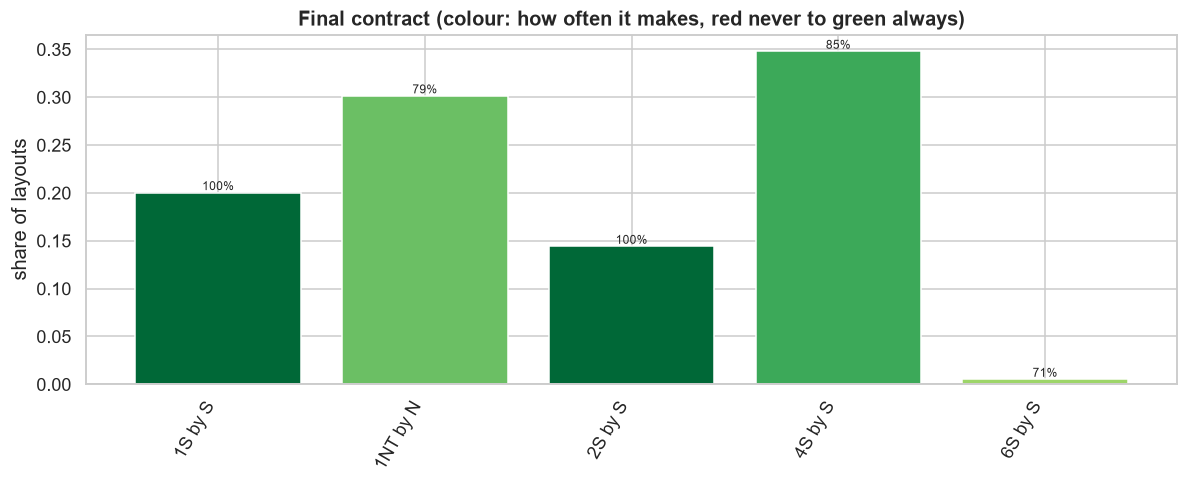

99.8% of layouts end in one of these 5 contracts; the rest are rarer
overall: the contract makes 88.4% of the time (card counter), 88.9% (simple); mean score for North/South +221


In [7]:
by_contract = played.groupby("contract").agg(share=("level", "size"), makes=("makes_counting", "mean"), mean_score=("ns_score_counting", "mean"),
                                           level=("level", "first"), strain=("strain", "first"))
by_contract["share"] /= len(df)
by_contract = by_contract.sort_values(["level", "strain"])
top = by_contract[by_contract.share >= 0.004]

fig, ax = plt.subplots(figsize=(11, 4.6))
bars = ax.bar(range(len(top)), top.share, color=plt.cm.RdYlGn(top.makes.values))
ax.set_xticks(range(len(top)), top.index, rotation=60, ha="right")
ax.set(ylabel="share of layouts", title="Final contract (colour: how often it makes, red never to green always)")
for i, (share, makes) in enumerate(zip(top.share, top.makes)):
    ax.text(i, share, f"{makes:.0%}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

print(f"{(top.share.sum()):.1%} of layouts end in one of these {len(top)} contracts; the rest are rarer")
print(f"overall: the contract makes {played.makes_counting.mean():.1%} of the time (card counter), {played.makes_simple.mean():.1%} (simple); "
      f"mean score for North/South {played.ns_score_counting.mean():+.0f}")

### The auctions

The first four bids of each auction (passes left out), the most common sequences, and how they turned out.

In [8]:
def seq_text(row):
    return " - ".join(bid_label(int(row[f"bid{k}"])) for k in (1, 2, 3, 4) if row[f"bid{k}"] > 0)

def bid_label(i):
    return "none" if i == 0 else f"{(i - 1) // 5 + 1}{'NT' if STRAINS[(i - 1) % 5] == 'notrump' else SYMBOL[STRAINS[(i - 1) % 5]]}"

df["sequence"] = df.apply(seq_text, axis=1)
played["sequence"] = df.loc[played.index, "sequence"]
seqs = played.groupby("sequence").agg(n=("level", "size"), makes=("makes_counting", "mean"), mean_score=("ns_score_counting", "mean"),
                                      final=("contract", lambda s: s.mode().iat[0]))
seqs["share"] = seqs.n / len(df)
seqs = seqs.sort_values("n", ascending=False)
rows_html = [[s, f"{r.share:.1%}", r.final, f"{r.makes:.0%}", f"{r.mean_score:+.0f}"] for s, r in seqs.head(14).iterrows()]
display(HTML(table_html(["first bids", "share", "usual final contract", "makes", "mean score"], rows_html,
                        caption=f"The {min(14, len(seqs))} most common of {len(seqs)} auction beginnings ({seqs.head(14).share.sum():.0%} of layouts)")))

first bids,share,usual final contract,makes,mean score
1♠ - 1NT,30.1%,1NT by N,79%,+106
1♠,20.0%,1S by S,100%,+141
1♠ - 2♠,14.4%,2S by S,100%,+174
1♠ - 2♦ - 4♠,11.8%,4S by S,79%,+345
1♠ - 2♣ - 4♠,7.8%,4S by S,88%,+393
1♠ - 3♠ - 4♠,7.4%,4S by S,93%,+411
1♠ - 2♥ - 4♠,5.3%,4S by S,80%,+349
1♠ - 4♠,2.5%,4S by S,98%,+453
1♠ - 2♦ - 4♠ - 6♠,0.3%,6S by S,70%,+673
1♠ - 6♠ - 7♠,0.2%,7S by S,36%,+497


### What partner's hand does

The same results against partner's points, from exact grouping of the 20,000 layouts. A game needs about 25 points between the two hands (10 from partner here).

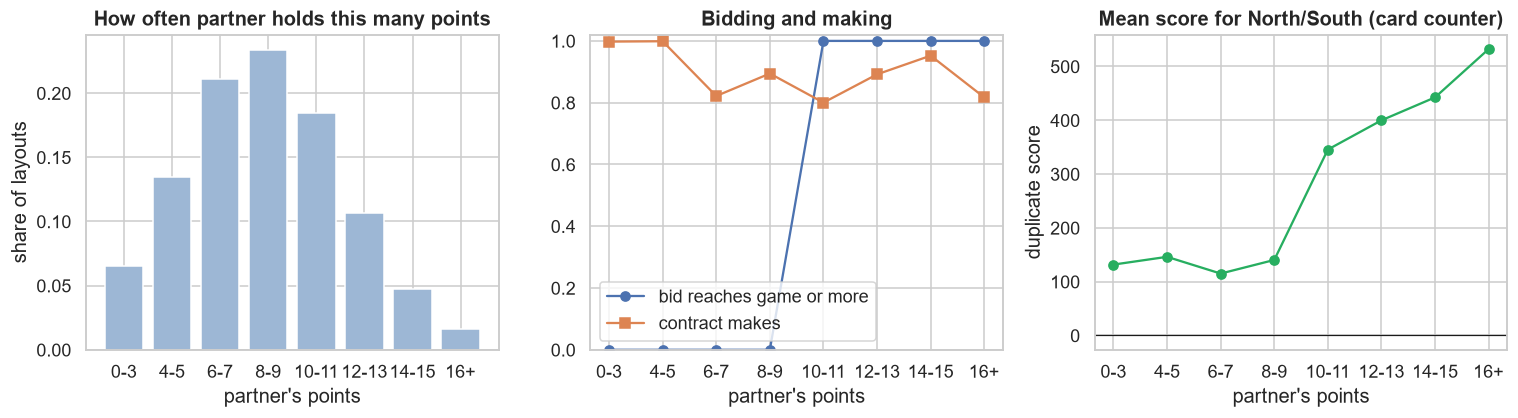

partner points,share,game reached,makes,mean tricks,mean score
0-3,6.6%,0%,100%,8.73,+132
4-5,13.5%,0%,100%,9.21,+146
6-7,21.1%,0%,82%,8.66,+115
8-9,23.4%,0%,89%,9.20,+140
10-11,18.4%,100%,80%,10.47,+346
12-13,10.7%,100%,89%,10.93,+400
14-15,4.7%,100%,95%,11.45,+443
16+,1.6%,100%,82%,11.89,+532


In [9]:
df["partner_hcp"] = df.ns_hcp - 15
played["partner_hcp"] = df.loc[played.index, "partner_hcp"]
bins = [-1, 3, 5, 7, 9, 11, 13, 15, 40]
labels = ["0-3", "4-5", "6-7", "8-9", "10-11", "12-13", "14-15", "16+"]
played["bin"] = pd.cut(played.partner_hcp, bins, labels=labels)
df["bin"] = pd.cut(df.partner_hcp, bins, labels=labels)
played["game_or_more"] = played.kind.isin(["game", "small slam", "grand slam"])
g = played.groupby("bin", observed=True).agg(n=("level", "size"), game=("game_or_more", "mean"), makes=("makes_counting", "mean"),
                                              score=("ns_score_counting", "mean"), tricks=("tricks_counting", "mean"))
g["share"] = g.n / len(df)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(g.index.astype(str), g.share, color="#9db7d5")
axes[0].set(title="How often partner holds this many points", ylabel="share of layouts", xlabel="partner's points")
axes[1].plot(g.index.astype(str), g.game, "o-", label="bid reaches game or more")
axes[1].plot(g.index.astype(str), g.makes, "s-", label="contract makes")
axes[1].set(title="Bidding and making", ylim=(0, 1.02), xlabel="partner's points")
axes[1].legend()
axes[2].plot(g.index.astype(str), g.score, "o-", color="#27ae60")
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set(title="Mean score for North/South (card counter)", xlabel="partner's points", ylabel="duplicate score")
plt.tight_layout()
plt.show()
display(HTML(table_html(["partner points", "share", "game reached", "makes", "mean tricks", "mean score"],
                        [[i, f"{r.share:.1%}", f"{r.game:.0%}", f"{r.makes:.0%}", f"{r.tricks:.2f}", f"{r.score:+.0f}"] for i, r in g.iterrows()])))

## 4. The play: how many tricks?

The same contracts played by the simple strategy and by the card counter, and, from the next section on, the double-dummy count.

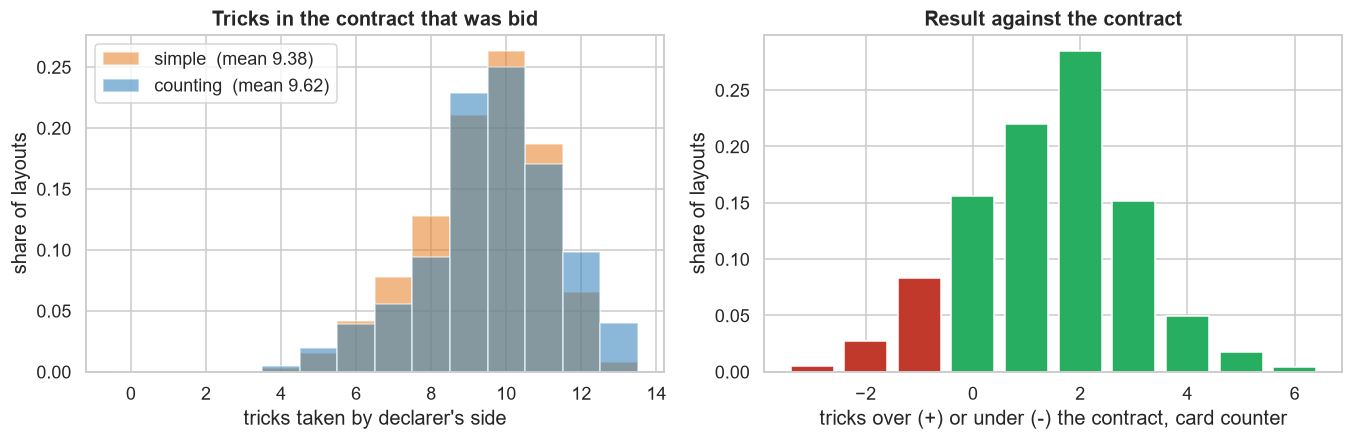

the card counter takes +0.25 tricks more than the simple strategy on average; more on 27.0% of layouts, fewer on 16.5%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
bins13 = np.arange(-0.5, 14.5)
for name, color in (("simple", "#e67e22"), ("counting", "#2c7fb8")):
    axes[0].hist(played[f"tricks_{name}"], bins=bins13, density=True, alpha=0.55, color=color, label=f"{name}  (mean {played[f'tricks_{name}'].mean():.2f})")
axes[0].set(xlabel="tricks taken by declarer's side", ylabel="share of layouts", title="Tricks in the contract that was bid")
axes[0].legend()
margin = (played.tricks_counting - played.need)
vals = margin.value_counts(normalize=True).sort_index()
axes[1].bar(vals.index, vals.values, color=["#c0392b" if v < 0 else "#27ae60" for v in vals.index])
axes[1].set(xlabel="tricks over (+) or under (-) the contract, card counter", title="Result against the contract", ylabel="share of layouts")
plt.tight_layout()
plt.show()
diff = played.tricks_counting - played.tricks_simple
print(f"the card counter takes {diff.mean():+.2f} tricks more than the simple strategy on average; "
      f"more on {(diff > 0).mean():.1%} of layouts, fewer on {(diff < 0).mean():.1%}")

## 5. What the cards allow: 1,000 layouts solved double-dummy

Perfect play from all four hands, for every strain and every declarer (`DoubleDummy`, about 45 ms a layout). These are fresh layouts (another seed), so the numbers are comparable to the above, not identical.

In [11]:
M = 1_000
t0 = time.perf_counter()
deals_dd = E.layouts(np.random.default_rng(12), M, 2, SOUTH_CARDS)
tables = np.array(DD.dd_tables(deals_dd))                           # (M, 5 strains, 4 declarers)
rows_dd = E.evaluate_deals(deals_dd, ["south"] * M, tables=tables)
print(f"{M:,} layouts solved, bid and played in {time.perf_counter() - t0:.0f} s")
dd = pd.DataFrame(rows_dd, columns=E.COLUMNS)
S, N = 2, 0

1,000 layouts solved, bid and played in 54 s


### Which contract is right for this hand?

If South were declarer in each contract: how often it makes (left), and the average score of bidding it every time, making or not (right). The best average score marks the contract the hand would be best advised to reach, knowing only its own cards.

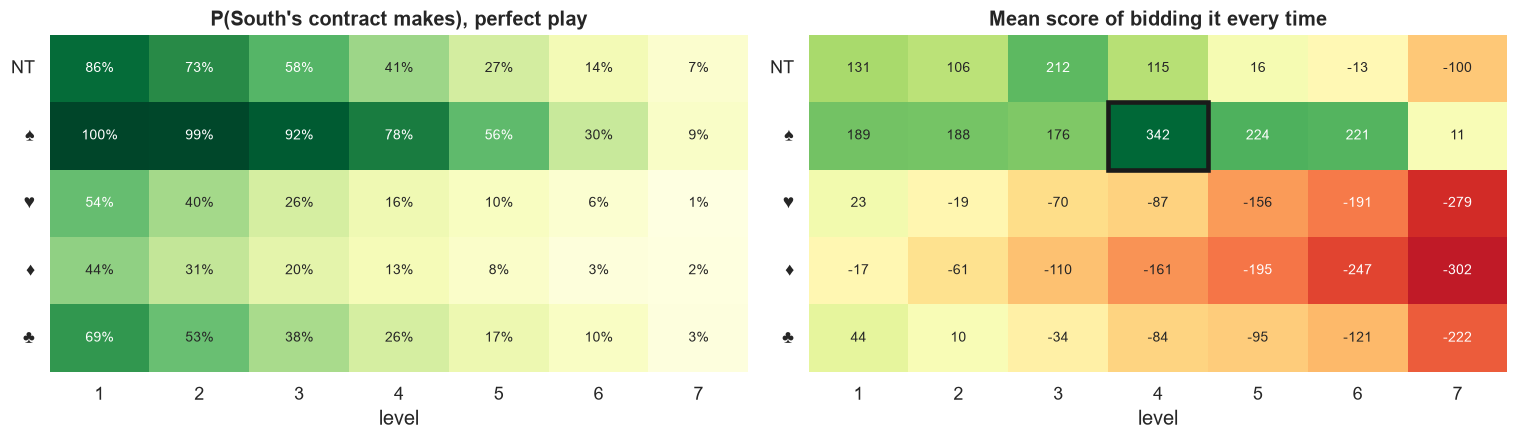

best on average: 4♠ by South, mean score +342, makes 78%
most tricks South can take in spades, double-dummy: mean 10.63, range 6 to 13


In [12]:
levels = np.arange(1, 8)
make = np.zeros((5, 7))
expect = np.zeros((5, 7))
for s, strain in enumerate(STRAINS):
    for L in levels:
        tricks = tables[:, s, S]
        make[s, L - 1] = (tricks >= L + 6).mean()
        expect[s, L - 1] = np.mean([score(Contract(int(L), strain, "south"), int(t)) for t in tricks])
order = [4, 3, 2, 1, 0]
ylabels = ["NT" if s == 4 else SYMBOL[STRAINS[s]] for s in order]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(make[order], annot=True, fmt=".0%", cmap="YlGn", vmin=0, vmax=1, ax=axes[0], xticklabels=levels, yticklabels=ylabels, cbar=False, annot_kws={"size": 9})
axes[0].set(title="P(South's contract makes), perfect play", xlabel="level")
sns.heatmap(expect[order], annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=axes[1], xticklabels=levels, yticklabels=ylabels, cbar=False, annot_kws={"size": 9})
axes[1].set(title="Mean score of bidding it every time", xlabel="level")
for ax in axes:
    ax.tick_params(axis="y", rotation=0)
best = np.unravel_index(expect.argmax(), expect.shape)
axes[1].add_patch(Rectangle((best[1], order.index(best[0])), 1, 1, fill=False, ec="k", lw=3))
plt.tight_layout()
plt.show()
print(f"best on average: {best[1] + 1}{'NT' if best[0] == 4 else SYMBOL[STRAINS[best[0]]]} by South, mean score {expect[best]:+.0f}, makes {make[best]:.0%}")
print(f"most tricks South can take in spades, double-dummy: mean {tables[:, 3, S].mean():.2f}, range {tables[:, 3, S].min()} to {tables[:, 3, S].max()}")

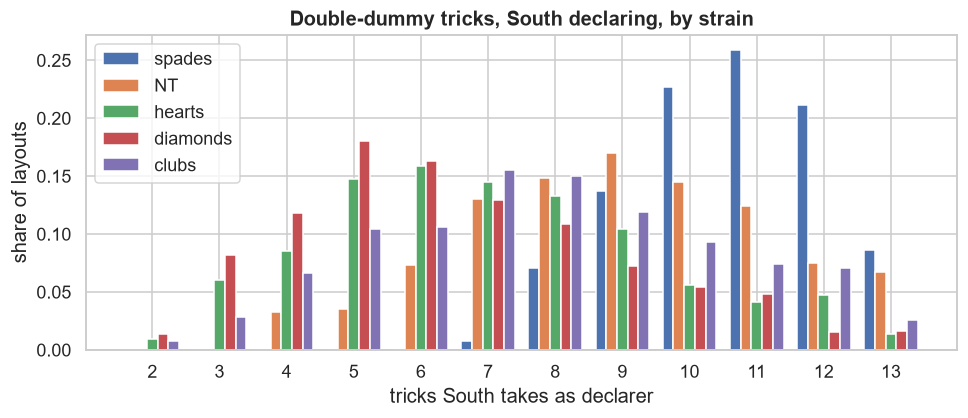

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.16
tr = np.arange(2, 14)
for k, s in enumerate([3, 4, 2, 1, 0]):
    counts = np.bincount(tables[:, s, S], minlength=14)[2:] / M
    ax.bar(tr + (k - 2) * width, counts, width, label="NT" if s == 4 else STRAINS[s])
ax.set(xlabel="tricks South takes as declarer", ylabel="share of layouts", title="Double-dummy tricks, South declaring, by strain")
ax.set_xticks(tr)
ax.legend()
plt.tight_layout()
plt.show()

### Was the bid right? The confusion matrix for this one hand

The bid reached against the highest contract that makes double-dummy for the side that bid, over the 1,000 layouts. Counts by kind of contract, and over/under/correct.

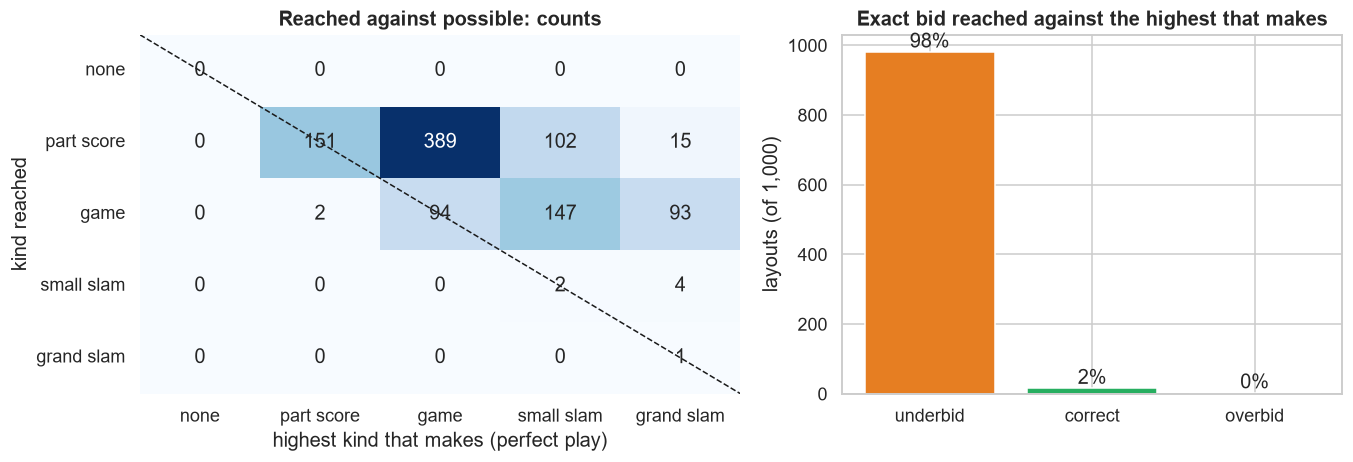

the contract reached makes with perfect play 96.2% of the time; mean score +259 reached against +644 for the best contract each layout allowed (a gap of 385 points a deal)
tricks in the contract reached: perfect play 10.13, card counter 9.62, simple 9.36


In [14]:
c = E.category_matrix(rows_dd)
share = c / c.sum(axis=1, keepdims=True).clip(1)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(c, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0], xticklabels=E.CATEGORIES, yticklabels=E.CATEGORIES)
axes[0].plot([0, 5], [0, 5], color="k", ls="--", lw=1)
axes[0].set(xlabel="highest kind that makes (perfect play)", ylabel="kind reached", title="Reached against possible: counts")
ou = E.over_under(rows_dd)
axes[1].bar(["underbid", "correct", "overbid"], [ou["underbid"], ou["correct"], ou["overbid"]], color=["#e67e22", "#27ae60", "#c0392b"])
axes[1].set(title="Exact bid reached against the highest that makes", ylabel="layouts (of 1,000)")
for i, v in enumerate([ou["underbid"], ou["correct"], ou["overbid"]]):
    axes[1].text(i, v, f"{v / M:.0%}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

reach = dd[dd.passed_out == 0]
made_dd = reach.dd_tricks >= reach.level + 6
print(f"the contract reached makes with perfect play {made_dd.mean():.1%} of the time; "
      f"mean score {reach.score_dd.mean():+.0f} reached against {reach.best_score.mean():+.0f} for the best contract each layout allowed "
      f"(a gap of {reach.best_score.mean() - reach.score_dd.mean():.0f} points a deal)")
print(f"tricks in the contract reached: perfect play {reach.dd_tricks.mean():.2f}, card counter {reach.tricks_counting.mean():.2f}, simple {reach.tricks_simple.mean():.2f}")

### Game: what the cards allow, and what the bidding does

A **game** here is 3NT, 4 of a major, or 5 of a minor made by North or South. Against partner's points: how often the cards allow one (perfect play), and how often the auction actually gets to game.

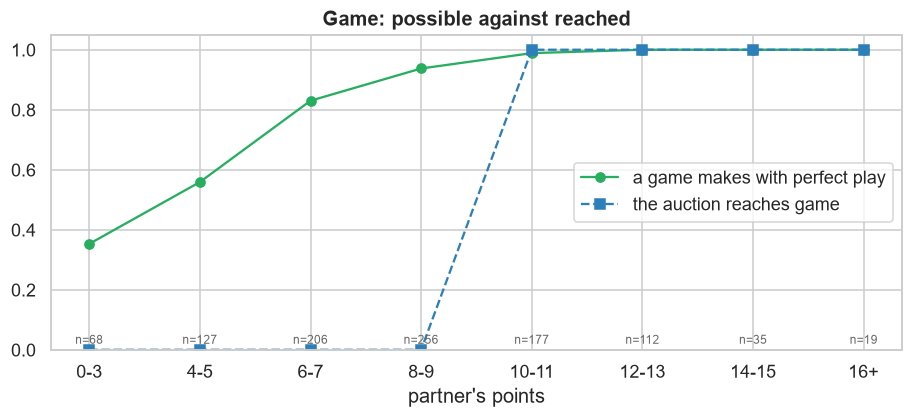

a game can be made on 84.7% of layouts, the auction reaches one on 34.3%


In [15]:
def game_makes(t):
    need = {0: 11, 1: 11, 2: 10, 3: 10, 4: 9}
    return any(t[s][seat] >= need[s] for s in range(5) for seat in (0, 2))

dd["game_possible"] = [game_makes(t) for t in tables]
dd["partner_hcp"] = dd.ns_hcp - 15
dd["bin"] = pd.cut(dd.partner_hcp, bins, labels=labels)
dd["kind"] = [E.CATEGORIES[E.category(max(l, 0), max(s, 0))] for l, s in zip(dd.level, dd.strain)]
dd["game_reached"] = dd.kind.isin(["game", "small slam", "grand slam"])
gd = dd.groupby("bin", observed=True).agg(n=("level", "size"), possible=("game_possible", "mean"), reached=("game_reached", "mean"))
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(gd.index.astype(str), gd.possible, "o-", color="#27ae60", label="a game makes with perfect play")
ax.plot(gd.index.astype(str), gd.reached, "s--", color="#2c7fb8", label="the auction reaches game")
for i, n in enumerate(gd.n):
    ax.text(i, 0.02, f"n={n}", ha="center", fontsize=8, color="#666")
ax.set(xlabel="partner's points", ylim=(0, 1.05), title="Game: possible against reached")
ax.legend()
plt.tight_layout()
plt.show()
print(f"a game can be made on {dd.game_possible.mean():.1%} of layouts, the auction reaches one on {dd.game_reached.mean():.1%}")

### Two extreme layouts

The layouts in which South takes the most and the fewest tricks in spades, double-dummy: the same hand, the other 39 cards placed differently.

In [16]:
for title, i in (("Most spade tricks", int(tables[:, 3, S].argmax())), ("Fewest spade tricks", int(tables[:, 3, S].argmin()))):
    display(HTML(f"<h4>{title}: South takes {tables[i][3][S]} tricks in spades</h4>"))
    display(HTML(deal_html(deals_dd[i], dealer="south") + dd_html(tables[i]) + auction_html(run_auction(deals_dd[i], "south"))))

## What to take from this

**What the cards could hold** (exact, checked against 20,000 sampled layouts to within 0.5 percentage points). Partner holds 8.3 points on average (standard deviation 3.3), so the pair averages 23.3: a little short of the 25 or so a game wants. Partner has 10 or more points 35% of the time, at least one spade 93% of the time (an 8+ card fit), at least three 31%, and is void 7%.

**What the bidding does.** South always opens 1 spade. It is never passed out. Then partner's points decide everything: with 10 or more partner always gets the pair to game, with fewer never. Across 20,000 layouts: 4 spades about 35%, 1NT played by North 30%, 1 spade left in 20%, 2 spades 14%, slams under 1%. Played by the card counter the contract makes 88% of the time (the simple strategy 89%), for an average of +221 to North/South.

**What the cards allow.** On 1,000 layouts solved double-dummy, a game makes on 85% of them, against the 34% where the auction reaches game. Even with partner at 6-7 points a game makes on about 83% of layouts and with 8-9 on about 94%, because the seven-card suit does the work. The best single contract for this hand, bid every time, is 4 spades by South: it makes 78% of the time and averages +342. The contracts reached score +259 on average, against +644 for the best contract each layout allowed (a gap of about 385 points a deal). The exact-bid scoring calls 98% of the bids under the highest contract that makes, which is harsh (it measures against the very top of what makes); by kind the picture is the same, three quarters of the contracts reached are below the highest kind that makes and almost none are above.

**Two things the system gets wrong for this hand,** both visible in the tables: (1) with a seven card suit South passes partner's 1NT response and plays 1NT in 30% of layouts, although South declaring 1 spade makes every time against 1NT's 86% with perfect play, and (2) the points rule never bids game below 10 points from partner. Both are on the improvement list in `PROJECT_MAP.md`.

**Play.** Against the same contracts the card counter takes 0.25 tricks more than the simple strategy on average (more tricks on 27% of layouts, fewer on 16.5%), and both fall short of perfect play (9.6 and 9.4 against 10.1 in the contracts reached).